 # Simulation output analysis

 Author: Moreno Marzolla

 Last modified: 2026-11-04
 
 --- 

In [191]:
import pandas as pd
df = pd.read_csv("mm1.csv")
df.head()

,jobId,arrivalTime,startTime,endTime
0,0,0.000,0.000,0.361
1,1,0.246,0.361,1.778
2,2,1.402,1.778,5.078
3,3,1.867,5.078,5.591
4,4,2.526,5.591,6.909


In [192]:
df["waitTime"] = df["startTime"] - df["arrivalTime"]
df["respTime"] = df["endTime"] - df["arrivalTime"]
df.head()

,jobId,arrivalTime,startTime,endTime,waitTime,respTime
0,0,0.000,0.000,0.361,0.000,0.361
1,1,0.246,0.361,1.778,0.115,1.532
2,2,1.402,1.778,5.078,0.376,3.676
3,3,1.867,5.078,5.591,3.211,3.724
4,4,2.526,5.591,6.909,3.065,4.383


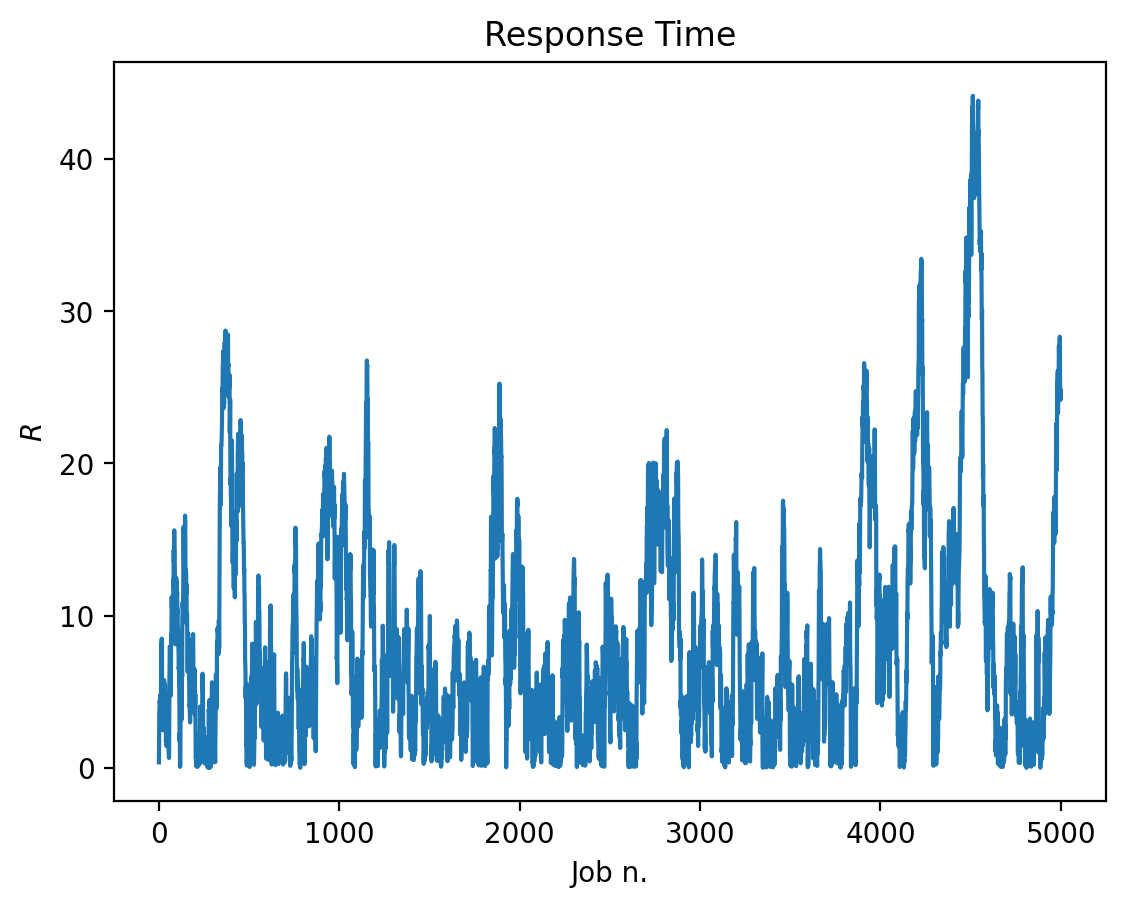

In [198]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 200
plt.plot(df["respTime"])
plt.xlabel("Job n.")
plt.ylabel(f"$R$")
plt.title("Response Time")
plt.show()

In [204]:
import numpy as np
rng = np.random.default_rng()
    
def generate_response_times(l=0.9, mu=1.0, n=1000):
    # arrivals[i] is the arrival time of job i
    arrivals = np.cumsum(rng.exponential(scale=1/l, size=n))
    # servtimes[i] is the service time of job i
    servtimes = rng.exponential(scale=1/mu, size=n)
    # endtimes[i] is the time job i completes service
    endtimes = np.zeros_like(arrivals)
    endtimes[0] = arrivals[0] + servtimes[0]
    for i in range(1,n):
        if (endtimes[i-1] < arrivals[i]):
            endtimes[i] = arrivals[i] + servtimes[i]
        else:
            endtimes[i] = endtimes[i-1] + servtimes[i]
    # resptimes[i] is the respose time experienced by job i
    resptimes = endtimes - arrivals
    return resptimes

l = 0.9
mu = 1.0
rho = l/mu
njobs = 5000
nrep = 200

expected_resp_time = rho/(mu-l) # expected response time according to queueing theory

r = np.zeros([njobs, nrep])
for i in range(nrep):
    r[:,i] = generate_response_times(l, mu, njobs)

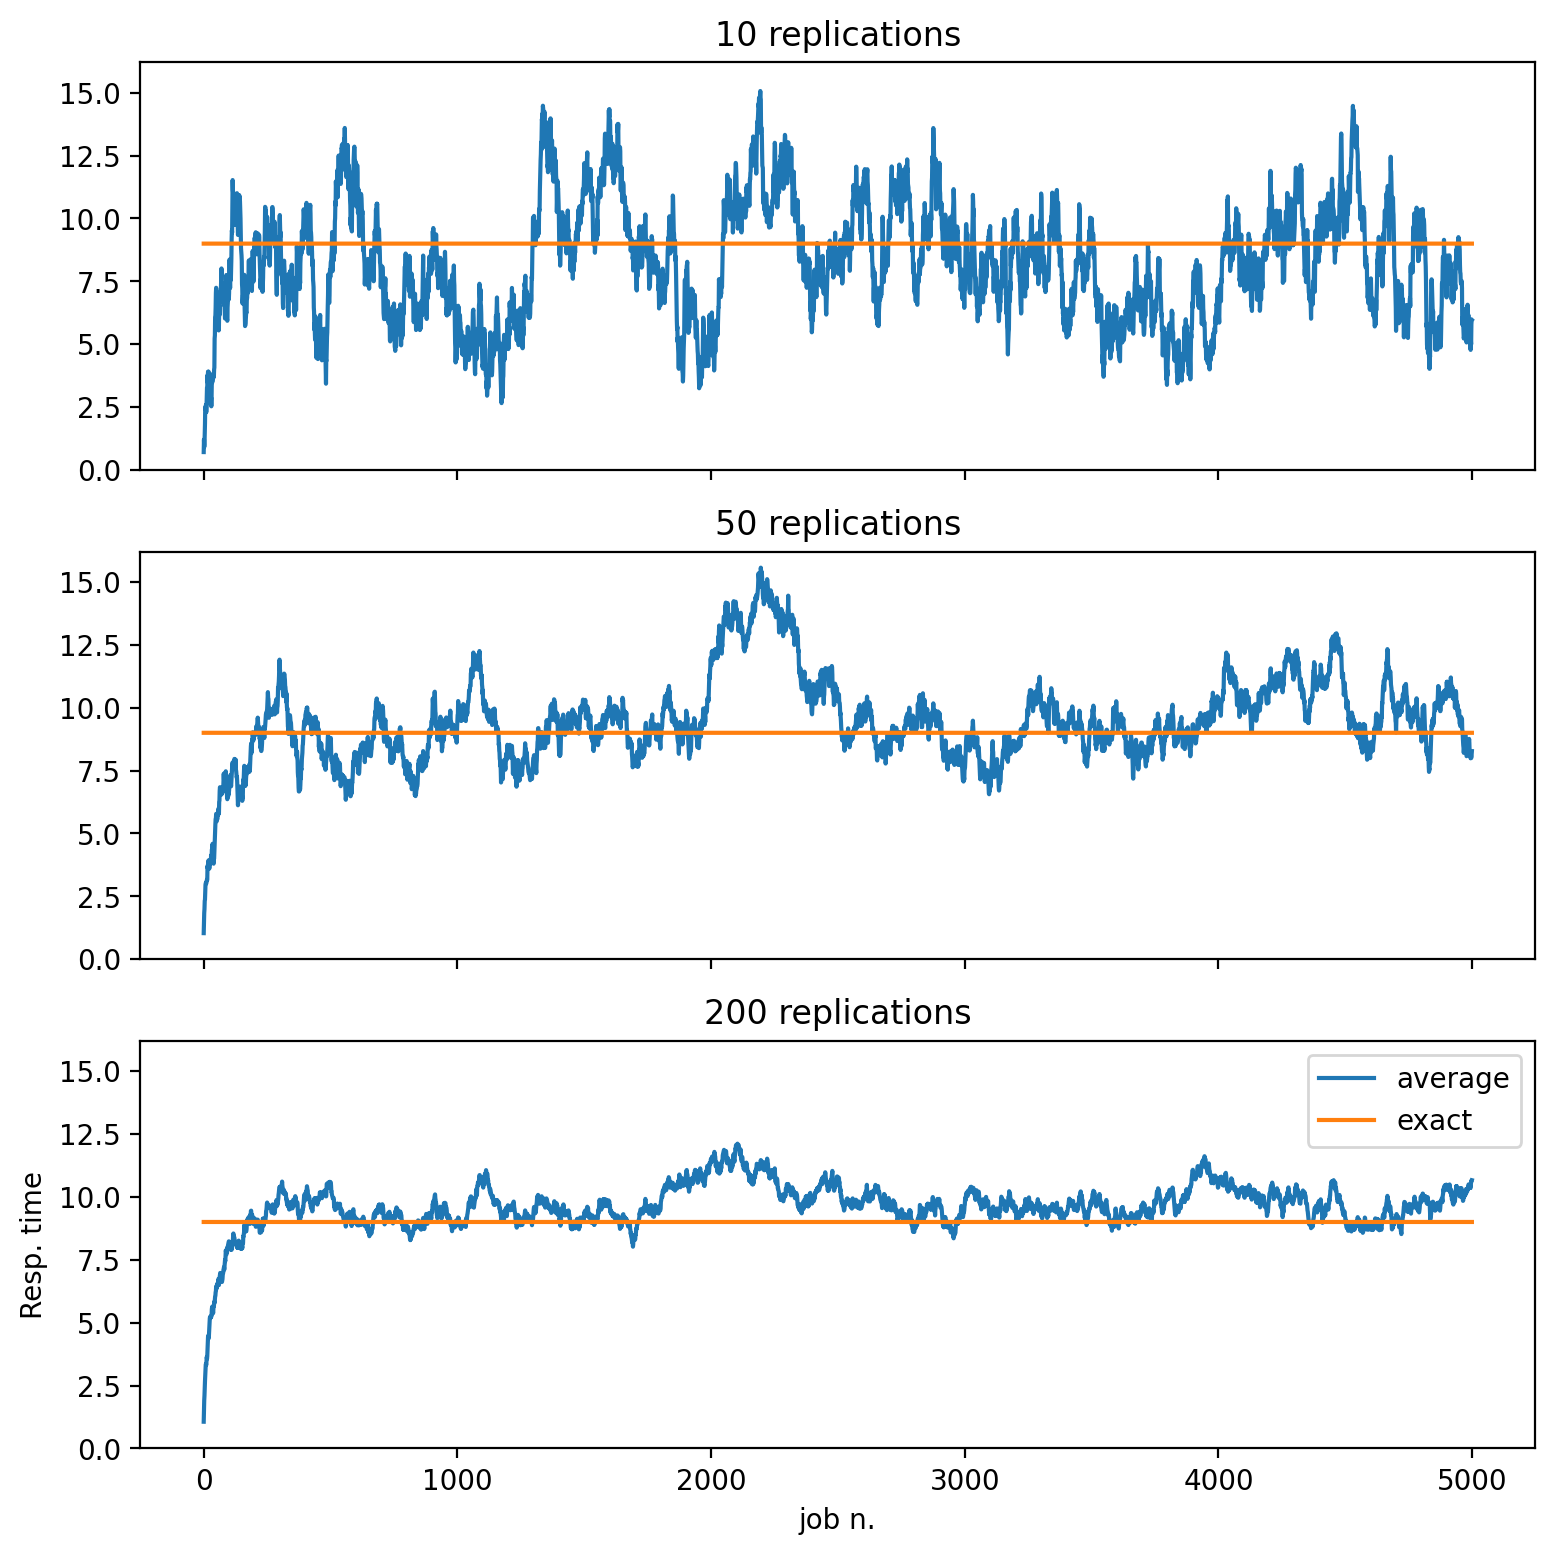

In [205]:
plt.subplots(3, 1, figsize=(9,9), sharex=True)
for idx, nr in enumerate([10, 50, 200], start=1): 
    plt.subplot(3, 1, idx)
    plt.plot(np.average(r[:,0:nr], axis=1))
    plt.plot(expected_resp_time*np.ones(njobs))
    plt.ylim([0, expected_resp_time*1.8])
    plt.title(f"{nr} replications")
plt.xlabel("job n.")
plt.ylabel("Resp. time")
plt.legend(["average", "exact"])
plt.show()